In [29]:
import pandas as pd

from config.settings import settings
from src.repository.postgres_db_connection import NhanesRepository

import importlib

import src.components.egfr as egfr_module

importlib.reload(egfr_module)
from src.components.egfr import add_egfr
import warnings

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.metrics import mean_pinball_loss
from sklearn.model_selection import KFold, train_test_split

repository = NhanesRepository.from_settings(settings)
df = pd.read_sql_query(
    "SELECT * FROM ml.cardiovascular_training",
    con=repository.engine,
)
df = add_egfr(df).drop(columns="scr")

print(df.columns.to_list())
print("Shape of the dataframe:", df.shape)
print("Total missing values:", df.isna().sum())
print(df.head())
df.describe()

['seqn', 'sex', 'age', 'race_eth', 'sdmvstra', 'sdmvpsu', 'height_cm', 'weight_kg', 'bmi', 'waist_cm', 'sbp', 'dbp', 'pulse', 'smoking', 'told_high_bp', 'bp_meds', 'told_high_chol', 'chol_meds', 'diabetes_dx', 'prediabetes_dx', 'insulin', 'diabetes_pills', 'non_hdl', 'hdl', 'hba1c', 'wt_lab', 'egfr']
Shape of the dataframe: (5681, 27)
Total missing values: seqn                 0
sex                  0
age                  0
race_eth             0
sdmvstra             0
sdmvpsu              0
height_cm           56
weight_kg           70
bmi                 77
waist_cm           255
sbp                177
dbp                177
pulse              177
smoking              7
told_high_bp         3
bp_meds              5
told_high_chol      27
chol_meds           15
diabetes_dx          0
prediabetes_dx    1005
insulin              0
diabetes_pills       5
non_hdl            519
hdl                519
hba1c              272
wt_lab               0
egfr               572
dtype: int64
       

,seqn,sex,age,race_eth,sdmvstra,sdmvpsu,height_cm,weight_kg,bmi,waist_cm,...,told_high_chol,chol_meds,prediabetes_dx,insulin,diabetes_pills,non_hdl,hdl,hba1c,wt_lab,egfr
count,5681.000000,5681.000000,5681.000000,5681.000000,5681.000000,5681.000000,5625.000000,5611.000000,5604.000000,5426.000000,...,5654.000000,5666.000000,4676.000000,5681.000000,5676.000000,5162.000000,5162.000000,5409.000000,5681.000000,5109.000000
mean,136346.034677,1.549727,52.447985,3.314557,179.716071,1.490583,167.176284,83.891422,29.953337,101.169775,...,0.408737,0.272150,0.144354,0.045767,0.113460,134.579233,54.375823,5.782215,40785.070098,90.270344
std,3442.560758,0.497565,16.362061,1.398370,4.271322,0.499955,10.023269,22.539062,7.436660,17.080736,...,0.491644,0.445106,0.351486,0.208997,0.317182,41.045884,14.807431,1.130917,32214.163152,21.427263
min,130378.000000,1.000000,20.000000,1.000000,173.000000,1.000000,133.000000,27.900000,11.100000,60.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,21.000000,22.000000,3.200000,0.000000,3.262490
25%,133318.000000,1.000000,38.000000,3.000000,176.000000,1.000000,159.800000,68.000000,24.700000,88.700000,...,0.000000,0.000000,0.000000,0.000000,0.000000,106.000000,44.000000,5.200000,19387.150559,76.591549
50%,136398.000000,2.000000,56.000000,3.000000,180.000000,1.000000,166.700000,80.400000,28.600000,99.600000,...,0.000000,0.000000,0.000000,0.000000,0.000000,131.000000,52.000000,5.500000,32128.947381,91.161923
75%,139317.000000,2.000000,66.000000,3.000000,183.000000,2.000000,174.500000,95.900000,33.700000,111.600000,...,1.000000,1.000000,0.000000,0.000000,0.000000,158.000000,62.000000,5.900000,51761.130297,104.730403
max,142309.000000,2.000000,79.000000,7.000000,187.000000,2.000000,200.700000,248.200000,74.800000,187.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,373.000000,159.000000,17.100000,241728.857241,172.347342


## Config


In [30]:


warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

TARGETS = ["non_hdl", "hdl", "hba1c", "egfr"]
FEATURES = [
    "sex",
    "age",
    "race_eth",
    "weight_kg",
    "waist_cm",
    "smoking",
    "told_high_bp",
    "bp_meds",
    "told_high_chol",
    "chol_meds",
    "diabetes_dx",
    "prediabetes_dx",
    "insulin",
    "diabetes_pills",
]
CATEGORICAL = ["sex", "race_eth", "smoking"]
QUANTILES = [0.05, 0.10, 0.25, 0.50, 0.75, 0.90, 0.95]
RANDOM_STATE = 42
N_SPLITS = 5
TEST_SIZE = 0.2

print("targets:", TARGETS)
print("features:", FEATURES)
print("quantiles:", QUANTILES)


targets: ['non_hdl', 'hdl', 'hba1c', 'egfr']
features: ['sex', 'age', 'race_eth', 'weight_kg', 'waist_cm', 'smoking', 'told_high_bp', 'bp_meds', 'told_high_chol', 'chol_meds', 'diabetes_dx', 'prediabetes_dx', 'insulin', 'diabetes_pills']
quantiles: [0.05, 0.1, 0.25, 0.5, 0.75, 0.9, 0.95]


## Feature preparation


In [31]:
work = df.copy()

# Inspect non-numeric / categorical-like columns
for col in [
    "sex",
    "race_eth",
    "smoking",
    "diabetes_dx",
    "prediabetes_dx",
    "insulin",
    "diabetes_pills",
]:
    print(f"{col}: {work[col].unique()[:20]!r}  dtype={work[col].dtype}")

# Map diabetes_dx yes/no(/borderline) -> numeric
dx_map = {"no": 0, "yes": 1, "borderline": 0.5}
if work["diabetes_dx"].dtype == object or str(work["diabetes_dx"].dtype) == "string":
    work["diabetes_dx"] = work["diabetes_dx"].map(dx_map)
    print("diabetes_dx mapped:", work["diabetes_dx"].value_counts(dropna=False).to_dict())

# Ensure numeric feature columns where expected
for col in FEATURES:
    if col not in CATEGORICAL:
        work[col] = pd.to_numeric(work[col], errors="coerce")

for col in CATEGORICAL:
    work[col] = work[col].astype("category")

print("\nTarget missingness / describe:")
for t in TARGETS:
    n_miss = work[t].isna().sum()
    print(f"  {t}: n={work[t].notna().sum()}, missing={n_miss} ({100 * n_miss / len(work):.1f}%)")
work[TARGETS].describe()


sex: array([1., 2.])  dtype=float64
race_eth: array([6., 3., 2., 1., 4., 7.])  dtype=float64
smoking: <StringArray>
['former', 'never', 'current', nan]
Length: 4, dtype: str  dtype=str
diabetes_dx: <StringArray>
['no', 'yes', 'borderline']
Length: 3, dtype: str  dtype=str
prediabetes_dx: array([ 0., nan,  1.])  dtype=float64
insulin: array([0, 1])  dtype=int64
diabetes_pills: array([ 0.,  1., nan])  dtype=float64

Target missingness / describe:
  non_hdl: n=5162, missing=519 (9.1%)
  hdl: n=5162, missing=519 (9.1%)
  hba1c: n=5409, missing=272 (4.8%)
  egfr: n=5109, missing=572 (10.1%)


,non_hdl,hdl,hba1c,egfr
count,5162.000000,5162.000000,5409.000000,5109.000000
mean,134.579233,54.375823,5.782215,90.270344
std,41.045884,14.807431,1.130917,21.427263
min,21.000000,22.000000,3.200000,3.262490
25%,106.000000,44.000000,5.200000,76.591549
50%,131.000000,52.000000,5.500000,91.161923
75%,158.000000,62.000000,5.900000,104.730403
max,373.000000,159.000000,17.100000,172.347342


## Helpers


In [32]:
def pinball_loss(y, q_pred, tau: float) -> float:
    return float(mean_pinball_loss(y, q_pred, alpha=tau))


def make_lgbm(tau: float, **params) -> lgb.LGBMRegressor:
    defaults = dict(
        objective="quantile",
        alpha=tau,
        n_estimators=2000,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=RANDOM_STATE,
        verbose=-1,
    )
    defaults.update(params)
    return lgb.LGBMRegressor(**defaults)


def fit_with_es(model, X_tr, y_tr, X_val, y_val):
    model.fit(
        X_tr,
        y_tr,
        eval_set=[(X_val, y_val)],
        eval_metric="quantile",
        callbacks=[lgb.early_stopping(100, verbose=False), lgb.log_evaluation(0)],
    )
    return model


def fix_crossing(pred_matrix: np.ndarray) -> np.ndarray:
    """Monotone rearrangement across quantile columns."""
    return np.sort(pred_matrix, axis=1)


def prepare_xy(frame: pd.DataFrame, target: str):
    sub = frame.dropna(subset=[target]).copy()
    X = sub[FEATURES].copy()
    y = sub[target].astype(float).values
    return X, y, sub.index


PARAM_GRID = [
    {"num_leaves": 15, "min_child_samples": 20},
    {"num_leaves": 15, "min_child_samples": 50},
    {"num_leaves": 31, "min_child_samples": 20},
    {"num_leaves": 31, "min_child_samples": 50},
]

print(f"{len(PARAM_GRID)} configs x {len(QUANTILES)} quantiles x {N_SPLITS} folds")


4 configs x 7 quantiles x 5 folds


## Train / test split (per target)


In [33]:
splits = {}
for target in TARGETS:
    X, y, idx = prepare_xy(work, target)
    X_train, X_test, y_train, y_test, idx_train, idx_test = train_test_split(
        X,
        y,
        idx,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
    )
    splits[target] = {
        "X_train": X_train.reset_index(drop=True),
        "X_test": X_test.reset_index(drop=True),
        "y_train": y_train,
        "y_test": y_test,
        "idx_train": idx_train,
        "idx_test": idx_test,
    }
    print(f"{target}: train={len(y_train)}, test={len(y_test)}")


non_hdl: train=4129, test=1033
hdl: train=4129, test=1033
hba1c: train=4327, test=1082
egfr: train=4087, test=1022


## Cross-validation + light tuning


In [34]:
# Collect one row per (target, hyperparam config, quantile, fold)
cv_rows = []

# 5-fold splitter on the training set only (test set stays untouched)
kf = KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

for target in TARGETS:
    X_train = splits[target]["X_train"]
    y_train = splits[target]["y_train"]
    print(f"\n=== {target} ===")

    # Try each LightGBM hyperparameter config in PARAM_GRID
    for cfg_i, cfg in enumerate(PARAM_GRID):
        cfg_name = f"leaves{cfg['num_leaves']}_mcs{cfg['min_child_samples']}"

        # Fit a separate quantile model for each tau (e.g. 0.05, 0.50, 0.95)
        for tau in QUANTILES:

            # Rotate which 1/5 of train is held out for validation
            for fold, (tr_ix, va_ix) in enumerate(kf.split(X_train)):
                X_tr, X_va = X_train.iloc[tr_ix], X_train.iloc[va_ix]
                y_tr, y_va = y_train[tr_ix], y_train[va_ix]

                # Build quantile LightGBM with this tau + config
                model = make_lgbm(tau, **cfg)
                # Train with early stopping on the fold's validation split
                fit_with_es(model, X_tr, y_tr, X_va, y_va)

                # Score how well predicted quantiles match y_va (lower is better)
                pred = model.predict(X_va)
                loss = pinball_loss(y_va, pred, tau)

                # Trees kept after early stopping (used later as n_estimators)
                best_iter = int(
                    getattr(model, "best_iteration_", model.n_estimators) or model.n_estimators
                )

                cv_rows.append(
                    {
                        "target": target,
                        "config": cfg_name,
                        "cfg_i": cfg_i,
                        "tau": tau,
                        "fold": fold,
                        "pinball": loss,
                        "best_iter": best_iter,
                    }
                )

        # Average pinball for this config across all taus and folds (progress print)
        mean_pin = np.mean(
            [r["pinball"] for r in cv_rows if r["target"] == target and r["config"] == cfg_name]
        )
        print(f"  {cfg_name}: mean pinball={mean_pin:.4f}")

# Raw fold-level results -> tidy table
cv_results = pd.DataFrame(cv_rows)

# Collapse folds: mean/std pinball and mean best_iter per (target, config, tau)
cv_summary = (
    cv_results.groupby(["target", "config", "tau"], as_index=False)
    .agg(
        pinball_mean=("pinball", "mean"),
        pinball_std=("pinball", "std"),
        best_iter_mean=("best_iter", "mean"),
    )
)

# Pick the winning config per target (lowest pinball averaged over all quantiles)
best_configs = {}
for target in TARGETS:
    by_cfg = (
        cv_summary[cv_summary["target"] == target]
        .groupby("config", as_index=False)["pinball_mean"]
        .mean()
        .sort_values("pinball_mean")
    )
    best = by_cfg.iloc[0]["config"]
    best_configs[target] = best
    print(f"best for {target}: {best} (avg pinball={by_cfg.iloc[0]['pinball_mean']:.4f})")

cv_summary.head(20)



=== non_hdl ===
  leaves15_mcs20: mean pinball=8.0297
  leaves15_mcs50: mean pinball=8.0149
  leaves31_mcs20: mean pinball=8.0749
  leaves31_mcs50: mean pinball=8.0312

=== hdl ===
  leaves15_mcs20: mean pinball=2.8140
  leaves15_mcs50: mean pinball=2.8150
  leaves31_mcs20: mean pinball=2.8315
  leaves31_mcs50: mean pinball=2.8291

=== hba1c ===
  leaves15_mcs20: mean pinball=0.1366
  leaves15_mcs50: mean pinball=0.1357
  leaves31_mcs20: mean pinball=0.1372
  leaves31_mcs50: mean pinball=0.1362

=== egfr ===
  leaves15_mcs20: mean pinball=3.3771
  leaves15_mcs50: mean pinball=3.3638
  leaves31_mcs20: mean pinball=3.4048
  leaves31_mcs50: mean pinball=3.3859
best for non_hdl: leaves15_mcs50 (avg pinball=8.0149)
best for hdl: leaves15_mcs20 (avg pinball=2.8140)
best for hba1c: leaves15_mcs50 (avg pinball=0.1357)
best for egfr: leaves15_mcs50 (avg pinball=3.3638)


,target,config,tau,pinball_mean,pinball_std,best_iter_mean
0,egfr,leaves15_mcs20,0.05,1.880973,0.068008,153.0
1,egfr,leaves15_mcs20,0.10,3.073129,0.095990,176.0
2,egfr,leaves15_mcs20,0.25,5.232748,0.164014,189.6
3,egfr,leaves15_mcs20,0.50,6.051216,0.139357,225.8
4,egfr,leaves15_mcs20,0.75,4.168574,0.058012,214.6
5,egfr,leaves15_mcs20,0.90,2.057226,0.043819,198.6
6,egfr,leaves15_mcs20,0.95,1.175857,0.032148,221.6
7,egfr,leaves15_mcs50,0.05,1.857490,0.053472,139.6
8,egfr,leaves15_mcs50,0.10,3.063229,0.098590,149.8
9,egfr,leaves15_mcs50,0.25,5.225380,0.170170,197.6


## Final fit + test evaluation


In [35]:
models = {t: {} for t in TARGETS}
test_preds = {}
eval_rows = []
interval_rows = []

for target in TARGETS:
    X_train = splits[target]["X_train"]
    X_test = splits[target]["X_test"]
    y_train = splits[target]["y_train"]
    y_test = splits[target]["y_test"]
    cfg_name = best_configs[target]
    cfg = PARAM_GRID[
        int(
            cv_results.loc[
                (cv_results["target"] == target) & (cv_results["config"] == cfg_name),
                "cfg_i",
            ].iloc[0]
        )
    ]

    pred_mat = np.zeros((len(y_test), len(QUANTILES)))
    for j, tau in enumerate(QUANTILES):
        sub = cv_summary[
            (cv_summary["target"] == target)
            & (cv_summary["config"] == cfg_name)
            & (cv_summary["tau"] == tau)
        ]
        n_est = max(50, int(round(sub["best_iter_mean"].iloc[0])))
        model = make_lgbm(tau, n_estimators=n_est, **cfg)
        model.fit(X_train, y_train)
        models[target][tau] = model
        pred_mat[:, j] = model.predict(X_test)

    pred_mat = fix_crossing(pred_mat)
    test_preds[target] = pred_mat

    for j, tau in enumerate(QUANTILES):
        q_pred = pred_mat[:, j]
        baseline = float(np.quantile(y_train, tau))
        model_loss = pinball_loss(y_test, q_pred, tau)
        base_loss = pinball_loss(y_test, np.full_like(y_test, baseline), tau)
        skill = 1.0 - model_loss / base_loss if base_loss > 0 else np.nan
        coverage = float(np.mean(y_test <= q_pred))
        cv_row = cv_summary[
            (cv_summary["target"] == target)
            & (cv_summary["config"] == cfg_name)
            & (cv_summary["tau"] == tau)
        ].iloc[0]
        eval_rows.append(
            {
                "target": target,
                "tau": tau,
                "config": cfg_name,
                "n_estimators": max(50, int(round(cv_row["best_iter_mean"]))),
                "test_pinball": model_loss,
                "baseline_pinball": base_loss,
                "skill": skill,
                "coverage": coverage,
                "cv_pinball_mean": float(cv_row["pinball_mean"]),
                "cv_pinball_std": float(cv_row["pinball_std"]),
            }
        )

    # Interval metrics
    q_map = {tau: pred_mat[:, j] for j, tau in enumerate(QUANTILES)}
    for lo, hi, name in [(0.05, 0.95, "90%"), (0.25, 0.75, "50%")]:
        lower, upper = q_map[lo], q_map[hi]
        cover = float(np.mean((y_test >= lower) & (y_test <= upper)))
        width = float(np.mean(upper - lower))
        interval_rows.append(
            {"target": target, "interval": name, "coverage": cover, "mean_width": width}
        )
    print(f"{target}: done (config={cfg_name})")

eval_df = pd.DataFrame(eval_rows)
interval_df = pd.DataFrame(interval_rows)
display(eval_df.round(4))
display(interval_df.round(4))


non_hdl: done (config=leaves15_mcs50)
hdl: done (config=leaves15_mcs20)
hba1c: done (config=leaves15_mcs50)
egfr: done (config=leaves15_mcs50)


,target,tau,config,n_estimators,test_pinball,baseline_pinball,skill,coverage,cv_pinball_mean,cv_pinball_std
0,non_hdl,0.05,leaves15_mcs50,105,3.3399,3.5436,0.0575,0.0697,3.2422,0.0562
1,non_hdl,0.10,leaves15_mcs50,184,5.8298,6.2369,0.0653,0.1423,5.5783,0.1302
2,non_hdl,0.25,leaves15_mcs50,194,10.8262,12.1070,0.1058,0.2953,10.3257,0.1669
3,non_hdl,0.50,leaves15_mcs50,191,14.0344,16.3693,0.1426,0.5402,13.5996,0.3404
4,non_hdl,0.75,leaves15_mcs50,189,12.3389,14.0324,0.1207,0.7522,11.7556,0.3688
5,non_hdl,0.90,leaves15_mcs50,159,7.5540,8.4636,0.1075,0.8848,7.1367,0.2856
6,non_hdl,0.95,leaves15_mcs50,133,4.8874,5.2675,0.0722,0.9409,4.4664,0.2766
7,hdl,0.05,leaves15_mcs20,133,1.0553,1.1500,0.0824,0.0668,1.0276,0.0197
8,hdl,0.10,leaves15_mcs20,170,1.8543,2.0581,0.0990,0.1346,1.7893,0.0516
9,hdl,0.25,leaves15_mcs20,141,3.5672,4.0557,0.1204,0.2604,3.4672,0.0779


,target,interval,coverage,mean_width
0,non_hdl,90%,0.8712,110.1252
1,non_hdl,50%,0.4569,41.5270
2,hdl,90%,0.8867,38.0953
3,hdl,50%,0.4511,14.5059
4,hba1c,90%,0.8965,1.6952
5,hba1c,50%,0.5148,0.5974
6,egfr,90%,0.8669,44.6249
7,egfr,50%,0.4432,19.8350


## Linear QuantReg baseline


In [36]:
IMPUTE_COLS = [
    "prediabetes_dx",
    "waist_cm",
    "weight_kg",
    "told_high_bp",
    "bp_meds",
    "told_high_chol",
    "chol_meds",
    "diabetes_dx",
    "insulin",
    "diabetes_pills",
]
# sex / race_eth are numeric codes; smoking is string-coded (never/former/current)
NUMERIC_CATS = ["sex", "race_eth"]

formula_rhs = (
    "C(sex) + age + C(race_eth) + weight_kg + waist_cm + C(smoking) "
    "+ told_high_bp + bp_meds + told_high_chol + chol_meds "
    "+ diabetes_dx + prediabetes_dx + insulin + diabetes_pills "
    "+ waist_cm_miss + prediabetes_dx_miss"
)


def make_linear_frame(X: pd.DataFrame, y: np.ndarray, train_medians: dict | None = None):
    frame = X.copy()
    for col in NUMERIC_CATS:
        frame[col] = frame[col].astype(float)
    # keep smoking as string for C(smoking); fill with training mode
    frame["smoking"] = frame["smoking"].astype(object)
    frame["waist_cm_miss"] = frame["waist_cm"].isna().astype(float)
    frame["prediabetes_dx_miss"] = frame["prediabetes_dx"].isna().astype(float)

    medians = train_medians or {}
    if train_medians is None:
        for col in IMPUTE_COLS:
            if col in frame.columns:
                med = float(pd.to_numeric(frame[col], errors="coerce").median())
                if np.isnan(med):
                    med = 0.0
                medians[col] = med
        mode = frame["smoking"].mode(dropna=True)
        medians["_smoking_mode"] = mode.iloc[0] if len(mode) else "never"
    for col, med in medians.items():
        if col == "_smoking_mode":
            continue
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors="coerce").fillna(med)
    frame["smoking"] = frame["smoking"].fillna(medians["_smoking_mode"])
    frame["y"] = y
    return frame, medians


quantreg_eval = []
quantreg_preds = {}

for target in TARGETS:
    X_train = splits[target]["X_train"]
    X_test = splits[target]["X_test"]
    y_train = splits[target]["y_train"]
    y_test = splits[target]["y_test"]

    train_df, medians = make_linear_frame(X_train, y_train, train_medians=None)
    test_df, _ = make_linear_frame(X_test, y_test, train_medians=medians)

    formula = f"y ~ {formula_rhs}"
    pred_mat = np.zeros((len(y_test), len(QUANTILES)))
    for j, tau in enumerate(QUANTILES):
        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                fit = smf.quantreg(formula, data=train_df).fit(q=float(tau))
            pred_mat[:, j] = fit.predict(test_df)
        except Exception as exc:
            print(f"QuantReg fail {target} tau={tau}: {exc}")
            pred_mat[:, j] = np.nan

    pred_mat = fix_crossing(np.nan_to_num(pred_mat, nan=np.nanmedian(pred_mat)))
    quantreg_preds[target] = pred_mat
    for j, tau in enumerate(QUANTILES):
        quantreg_eval.append(
            {
                "target": target,
                "tau": tau,
                "test_pinball": pinball_loss(y_test, pred_mat[:, j], tau),
            }
        )
    print(f"QuantReg {target}: done")

qr_eval_df = pd.DataFrame(quantreg_eval)
display(qr_eval_df.round(4))


QuantReg non_hdl: done
QuantReg hdl: done
QuantReg hba1c: done
QuantReg egfr: done


,target,tau,test_pinball
0,non_hdl,0.05,3.3683
1,non_hdl,0.10,5.8279
2,non_hdl,0.25,11.0102
3,non_hdl,0.50,14.6251
4,non_hdl,0.75,12.7622
5,non_hdl,0.90,7.7262
6,non_hdl,0.95,4.8552
7,hdl,0.05,1.0362
8,hdl,0.10,1.8379
9,hdl,0.25,3.5918


## Visualizations

Per target: calibration, pinball loss vs tau, and fan chart.


============================================================ non_hdl


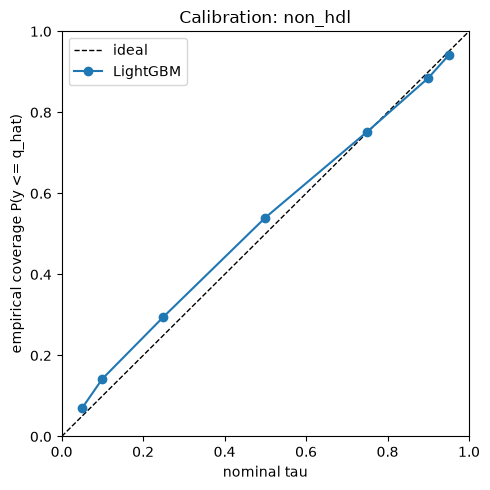

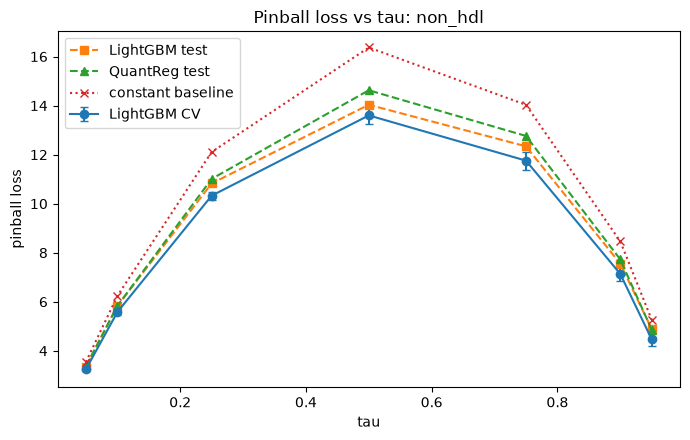

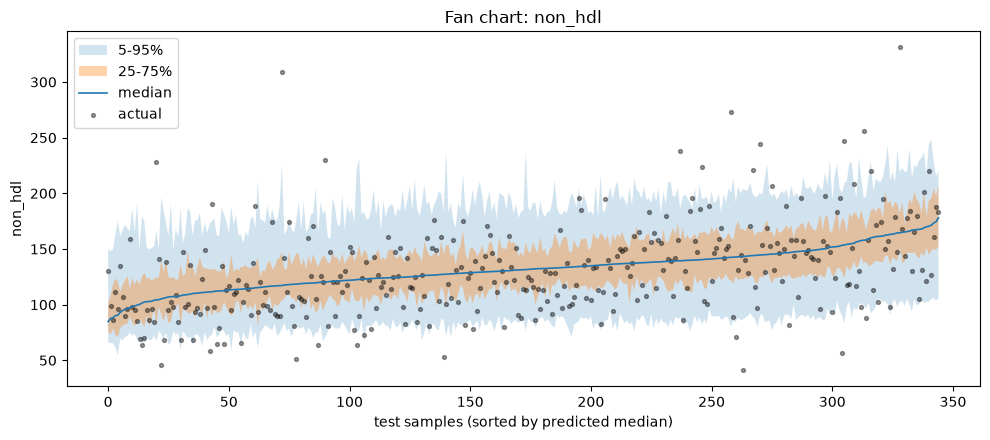

============================================================ hdl


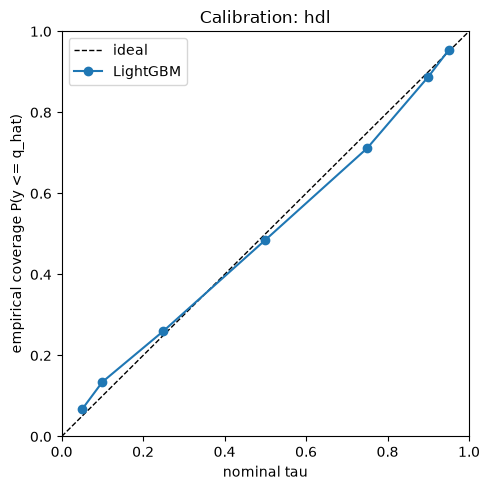

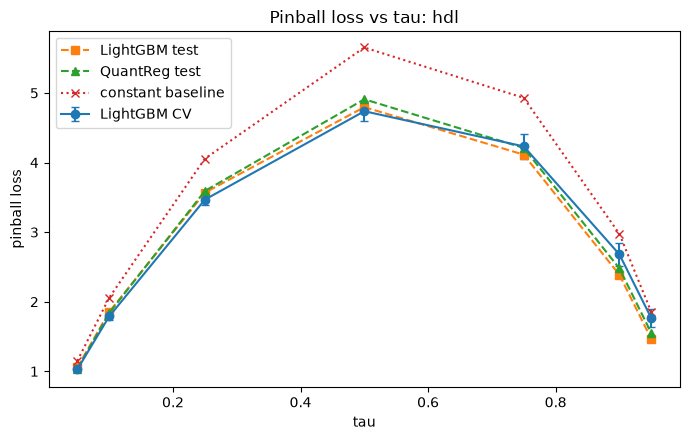

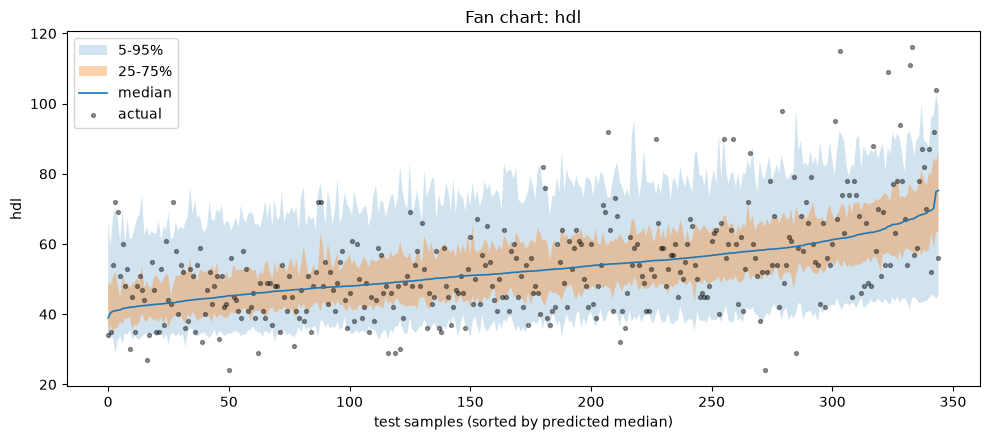

============================================================ hba1c


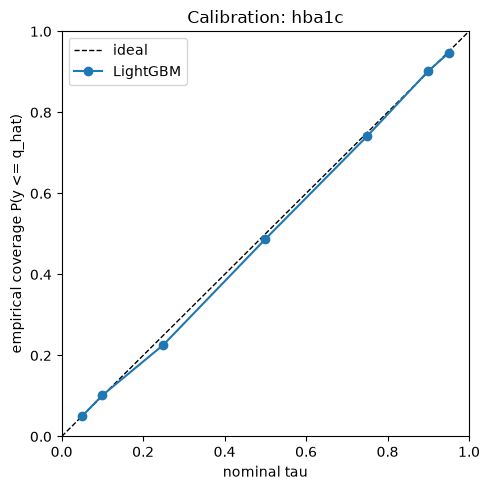

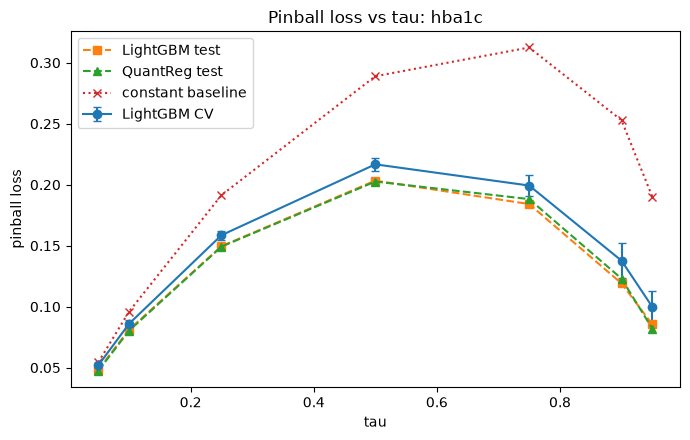

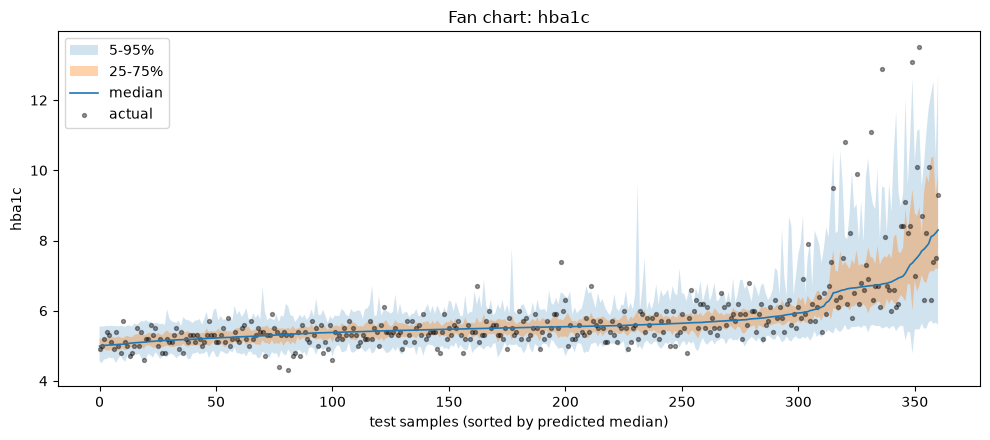

============================================================ egfr


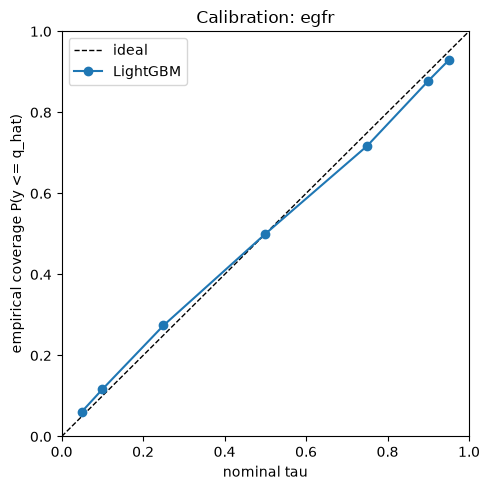

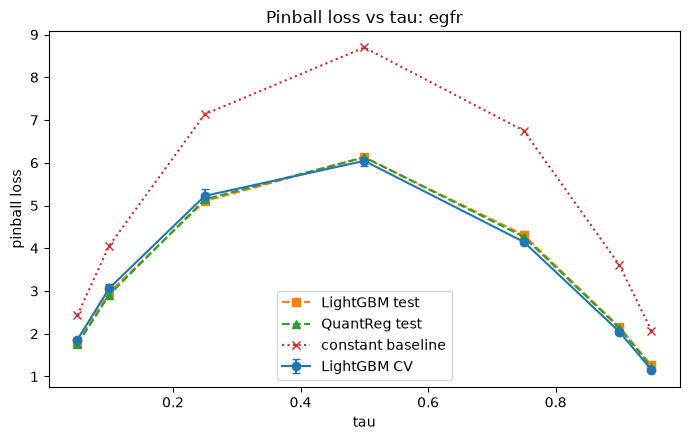

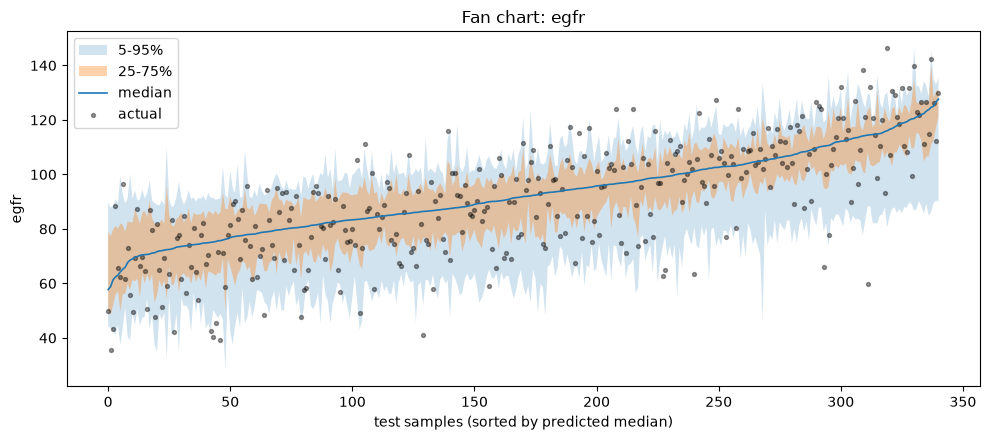

In [37]:
def plot_calibration(target: str):
    sub = eval_df[eval_df["target"] == target]
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="ideal")
    ax.plot(sub["tau"], sub["coverage"], "o-", label="LightGBM")
    ax.set_xlabel("nominal tau")
    ax.set_ylabel("empirical coverage P(y <= q_hat)")
    ax.set_title(f"Calibration: {target}")
    ax.legend()
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)
    fig.tight_layout()
    plt.show()


def plot_pinball_vs_tau(target: str):
    lgb_sub = eval_df[eval_df["target"] == target]
    qr_sub = qr_eval_df[qr_eval_df["target"] == target]
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.errorbar(
        lgb_sub["tau"],
        lgb_sub["cv_pinball_mean"],
        yerr=lgb_sub["cv_pinball_std"],
        fmt="o-",
        label="LightGBM CV",
        capsize=3,
    )
    ax.plot(lgb_sub["tau"], lgb_sub["test_pinball"], "s--", label="LightGBM test")
    ax.plot(qr_sub["tau"], qr_sub["test_pinball"], "^--", label="QuantReg test")
    ax.plot(lgb_sub["tau"], lgb_sub["baseline_pinball"], "x:", label="constant baseline")
    ax.set_xlabel("tau")
    ax.set_ylabel("pinball loss")
    ax.set_title(f"Pinball loss vs tau: {target}")
    ax.legend()
    fig.tight_layout()
    plt.show()


def plot_fan_chart(target: str, n_show: int = 300):
    y_test = splits[target]["y_test"]
    pred = test_preds[target]
    q_map = {tau: pred[:, j] for j, tau in enumerate(QUANTILES)}
    order = np.argsort(q_map[0.50])
    if len(order) > n_show:
        step = max(1, len(order) // n_show)
        order = order[::step]
    x = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.fill_between(x, q_map[0.05][order], q_map[0.95][order], alpha=0.2, label="5-95%")
    ax.fill_between(x, q_map[0.25][order], q_map[0.75][order], alpha=0.35, label="25-75%")
    ax.plot(x, q_map[0.50][order], color="C0", lw=1.2, label="median")
    ax.scatter(x, y_test[order], s=8, alpha=0.4, color="k", label="actual")
    ax.set_xlabel("test samples (sorted by predicted median)")
    ax.set_ylabel(target)
    ax.set_title(f"Fan chart: {target}")
    ax.legend()
    fig.tight_layout()
    plt.show()


for target in TARGETS:
    print("=" * 60, target)
    plot_calibration(target)
    plot_pinball_vs_tau(target)
    plot_fan_chart(target)


## Summary


In [38]:
summary_rows = []
for target in TARGETS:
    e = eval_df[eval_df["target"] == target]
    qr = qr_eval_df[qr_eval_df["target"] == target]
    iv90 = interval_df[(interval_df["target"] == target) & (interval_df["interval"] == "90%")].iloc[0]
    e50 = e[e["tau"] == 0.50].iloc[0]
    summary_rows.append(
        {
            "target": target,
            "best_config": best_configs[target],
            "cv_pinball_mean_all_tau": float(e["cv_pinball_mean"].mean()),
            "test_pinball_tau50": float(e50["test_pinball"]),
            "avg_skill": float(e["skill"].mean()),
            "coverage_tau50": float(e50["coverage"]),
            "interval_90_coverage": float(iv90["coverage"]),
            "interval_90_width": float(iv90["mean_width"]),
            "lgbm_mean_pinball": float(e["test_pinball"].mean()),
            "quantreg_mean_pinball": float(qr["test_pinball"].mean()),
            "lgbm_better": float(e["test_pinball"].mean()) < float(qr["test_pinball"].mean()),
        }
    )

summary_df = pd.DataFrame(summary_rows)
display(summary_df.round(4))

cmp = eval_df[["target", "tau", "test_pinball"]].rename(columns={"test_pinball": "lgbm"})
cmp = cmp.merge(
    qr_eval_df.rename(columns={"test_pinball": "quantreg"}),
    on=["target", "tau"],
)
display(cmp.round(4))


,target,best_config,cv_pinball_mean_all_tau,test_pinball_tau50,avg_skill,coverage_tau50,interval_90_coverage,interval_90_width,lgbm_mean_pinball,quantreg_mean_pinball,lgbm_better
0,non_hdl,leaves15_mcs50,8.0149,14.0344,0.0959,0.5402,0.8712,110.1252,8.4015,8.5964,True
1,hdl,leaves15_mcs20,2.8140,4.7965,0.1466,0.4850,0.8867,38.0953,2.7482,2.8021,True
2,hba1c,leaves15_mcs50,0.1357,0.2033,0.3244,0.4871,0.8965,1.6952,0.1244,0.1247,True
3,egfr,leaves15_mcs50,3.3638,6.1262,0.3244,0.5000,0.8669,44.6249,3.3873,3.3660,False


,target,tau,lgbm,quantreg
0,non_hdl,0.05,3.3399,3.3683
1,non_hdl,0.10,5.8298,5.8279
2,non_hdl,0.25,10.8262,11.0102
3,non_hdl,0.50,14.0344,14.6251
4,non_hdl,0.75,12.3389,12.7622
5,non_hdl,0.90,7.5540,7.7262
6,non_hdl,0.95,4.8874,4.8552
7,hdl,0.05,1.0553,1.0362
8,hdl,0.10,1.8543,1.8379
9,hdl,0.25,3.5672,3.5918
